In [1]:
%pip install rdkit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 35.1 MB/s  0:00:00


In [2]:
from rdkit import Chem, rdBase

print("RDKit version:", rdBase.rdkitVersion)

molecule = Chem.MolFromSmiles("CCO")
print("Number of atoms:", molecule.GetNumAtoms())

RDKit version: 2026.09.1
Number of atoms: 3


In [3]:
from rdkit.Chem import Descriptors, Crippen, Lipinski, rdMolDescriptors

# Create an ethanol molecule from its SMILES
molecule = Chem.MolFromSmiles("CCO")

print("Compound: Ethanol")
print("Molecular weight:", round(Descriptors.MolWt(molecule), 2), "g/mol")
print("Calculated LogP:", round(Crippen.MolLogP(molecule), 2))
print("TPSA:", round(rdMolDescriptors.CalcTPSA(molecule), 2), "Å²")
print("Hydrogen-bond donors:", Lipinski.NumHDonors(molecule))
print("Hydrogen-bond acceptors:", Lipinski.NumHAcceptors(molecule))

Compound: Ethanol
Molecular weight: 46.07 g/mol
Calculated LogP: -0.0
TPSA: 20.23 Å²
Hydrogen-bond donors: 1
Hydrogen-bond acceptors: 1


In [4]:
import pandas as pd
from rdkit import Chem
from rdkit.Chem import Descriptors, Crippen, Lipinski, rdMolDescriptors

# Example compounds: name and SMILES
compounds = [
    ("Ethanol", "CCO"),
    ("Acetic acid", "CC(=O)O"),
    ("Benzene", "c1ccccc1"),
    ("Phenol", "Oc1ccccc1"),
    ("Aspirin", "CC(=O)Oc1ccccc1C(=O)O")
]

results = []

for name, smiles in compounds:
    molecule = Chem.MolFromSmiles(smiles)

    if molecule is None:
        print(f"Invalid SMILES for {name}: {smiles}")
        continue

    results.append({
        "Compound": name,
        "SMILES": smiles,
        "MW (g/mol)": Descriptors.MolWt(molecule),
        "LogP": Crippen.MolLogP(molecule),
        "TPSA (Å²)": rdMolDescriptors.CalcTPSA(molecule),
        "HBD": Lipinski.NumHDonors(molecule),
        "HBA": Lipinski.NumHAcceptors(molecule)
    })

# Keep full precision in the data; round only the displayed table
df = pd.DataFrame(results)
display(df.round(2))

,Compound,SMILES,MW (g/mol),LogP,TPSA (Å²),HBD,HBA
0,Ethanol,CCO,46.07,-0.00,20.23,1,1
1,Acetic acid,CC(=O)O,60.05,0.09,37.30,1,1
2,Benzene,c1ccccc1,78.11,1.69,0.00,0,0
3,Phenol,Oc1ccccc1,94.11,1.39,20.23,1,1
4,Aspirin,CC(=O)Oc1ccccc1C(=O)O,180.16,1.31,63.60,1,3


In [5]:
# Save the table without the extra row-index column
df.to_csv("molecular_properties.csv", index=False, encoding="utf-8-sig")

# Download the file from Colab to your computer
from google.colab import files
files.download("molecular_properties.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

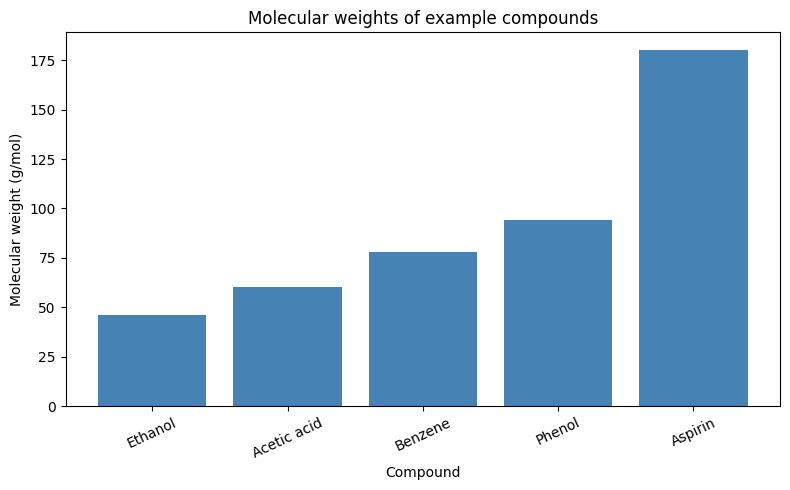

In [6]:
import matplotlib.pyplot as plt

# Compare molecular weights of the five example compounds
fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(df["Compound"], df["MW (g/mol)"], color="steelblue")

ax.set_xlabel("Compound")
ax.set_ylabel("Molecular weight (g/mol)")
ax.set_title("Molecular weights of example compounds")
ax.tick_params(axis="x", rotation=25)

fig.tight_layout()
fig.savefig("molecular_weight_comparison.png", dpi=300)
plt.show()

In [7]:
from google.colab import files

files.download("molecular_weight_comparison.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>